# 01 · Exploração da rede da dublagem brasileira

Primeiro olhar sobre `data/processed/elenco_limpo.csv`, a tabela personagem → ator original → dublador extraída da [Dublapédia](https://dublagem.fandom.com) (CC BY-SA 3.0) e limpa por `scripts/clean.py` (ver [reports/01_limpeza.md](../reports/01_limpeza.md)).

Os cálculos ficam em `scripts/explore.py`; aqui só se importam os agregados e se desenham os gráficos. Nenhuma célula mostra linhas brutas, só contagens e top-N.

Para refazer: `make collect parse clean-data` e depois `make notebooks`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import Markdown, display

import explore as ex

ex.style()
rows = ex.load()
milhar = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))

def tabela(pares, cab=("", "")):
    linhas = [f"| {cab[0]} | {cab[1]} |", "|---|---:|"] + [f"| {k} | {v} |" for k, v in pares]
    display(Markdown("\n".join(linhas)))

## 1. Tamanho da base

Cada linha é um papel: um personagem, numa versão de uma obra, com o dublador que o fez. Uma mesma pessoa aparece com um id só (`p:` quando tem ficha na Dublapédia, `n:` quando só tem o nome).

In [2]:
tabela([(k, f"{v:,}".replace(",", ".") if isinstance(v, int) else v) for k, v in ex.resumo(rows).items()], ("", "total"))

|  | total |
|---|---:|
| linhas (personagem → dublador) | 420.758 |
| obras | 13.670 |
| franquias | 10.074 |
| dubladores (ids) | 6.774 |
| atores originais (ids) | 109.628 |
| estúdios | 427 |
| anos | 1922–2030 |

## 2. Cobertura por mídia

Filmes são quase metade das obras (6,2 mil de 13,7 mil), mas pesam menos nos papéis: uma série tem, em média, muito mais personagens catalogados que um filme. Animação (séries animadas, anime e filmes animados) responde por cerca de um terço dos papéis.

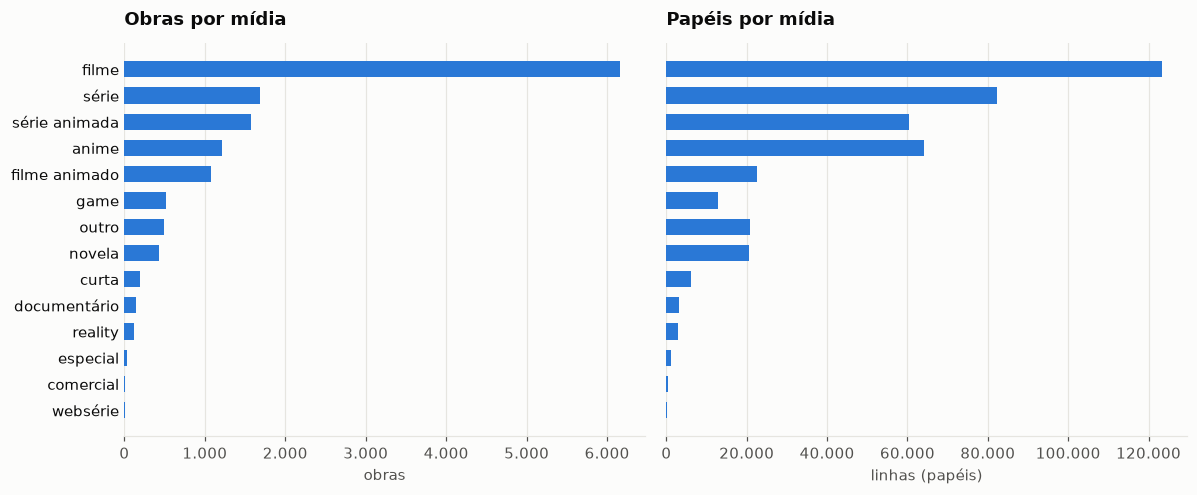

In [3]:
mid = ex.por_midia(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
ex.barh(axes[0], [m for m, _, _ in mid], [o for _, o, _ in mid], "Obras por mídia", "obras")
ex.barh(axes[1], [m for m, _, _ in mid], [l for _, _, l in mid], "Papéis por mídia", "linhas (papéis)")
for ax in axes: ax.xaxis.set_major_formatter(milhar)
fig.tight_layout()

## 3. Cobertura por década

A década vem do primeiro ano da obra (o lançamento original, não a data da dublagem). A década de 2020 ainda está em curso (vai até 2026 nesta coleta) e já é a maior. O que a base cobre de cada época depende do que os editores da Dublapédia catalogaram, então ela mede a atividade da wiki tanto quanto a da dublagem.

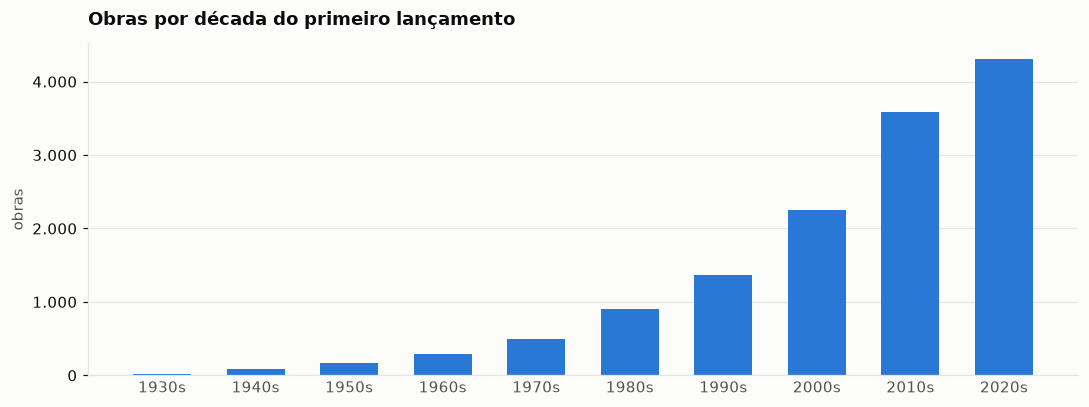

In [4]:
dec = ex.por_decada(rows)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar([str(d) + "s" for d in dec], list(dec.values()), width=0.62, color=ex.BLUE)
ax.set_title("Obras por década do primeiro lançamento")
ax.set_ylabel("obras"); ax.yaxis.set_major_formatter(milhar)
ax.grid(axis="x", visible=False); ax.tick_params(axis="x", length=0)
fig.tight_layout()

Separando as quatro mídias com mais obras, em pequenos múltiplos com o mesmo eixo: filmes crescem a cada década; séries live-action e anime quase dobram dos anos 2010 para os 2020, mesmo com a década incompleta; séries animadas são as únicas que caem.

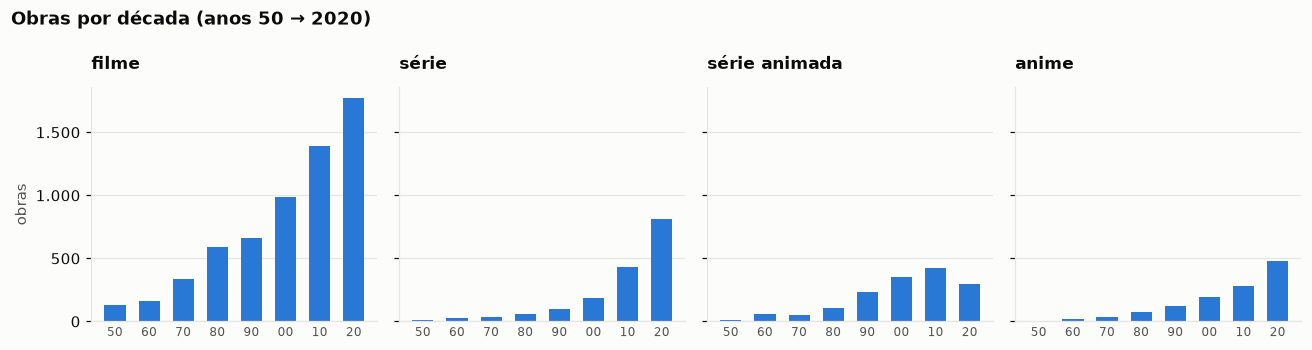

In [5]:
mids = ["filme", "série", "série animada", "anime"]
md = ex.midia_por_decada(rows, mids)
decs = sorted({d for m in mids for d in md[m]})
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
for ax, m in zip(axes, mids):
    ax.bar([f"{d % 100:02d}" for d in decs], [md[m][d] for d in decs], width=0.62, color=ex.BLUE)
    ax.set_title(m, fontsize=11); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", length=0, labelsize=8)
axes[0].set_ylabel("obras"); axes[0].yaxis.set_major_formatter(milhar)
fig.suptitle("Obras por década (anos 50 → 2020)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

## 4. Dubladores mais frequentes

"Papéis" conta linhas: o mesmo personagem em duas versões (dublagem e redublagem) conta duas vezes. Marcadores de vaga ("Por Confirmar", "?") não entram; as vozes recorrentes sem nome ("Dublador Desconhecido nº 9"), que têm ficha própria, entram como pessoas. O topo é quase todo do Rio de Janeiro (contagem pelas categorias de cidade das fichas, abaixo).

| dublador | papéis / obras |
|---|---:|
| Mauro Ramos | 2511 papéis em 1828 obras |
| Márcio Simões | 2075 papéis em 1618 obras |
| Júlio Chaves | 2024 papéis em 1479 obras |
| Guilherme Briggs | 1958 papéis em 1228 obras |
| Alexandre Moreno | 1829 papéis em 1442 obras |
| Luiz Carlos Persy | 1815 papéis em 1266 obras |
| Ronaldo Júlio | 1797 papéis em 1244 obras |
| Sergio Stern | 1791 papéis em 1222 obras |
| Carlos Seidl | 1747 papéis em 1111 obras |
| Maurício Berger | 1638 papéis em 1189 obras |

| categoria de cidade (pode ter as duas) | no top 20 |
|---|---:|
| Rio de Janeiro | 19 de 20 |
| São Paulo | 8 de 20 |

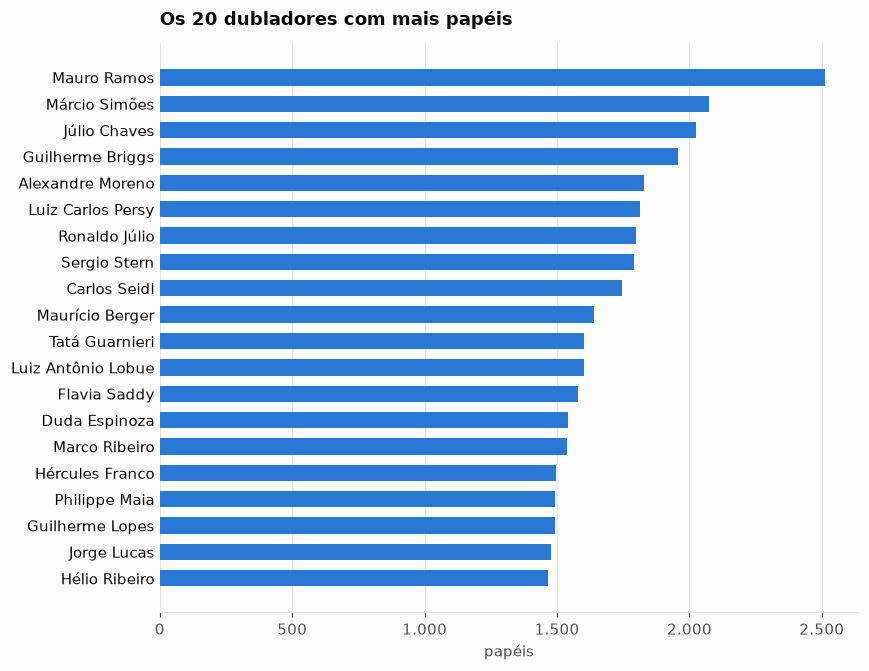

In [6]:
top = ex.top_dubladores(rows, 20)
fig, ax = plt.subplots(figsize=(8, 6.2))
ex.barh(ax, [n for n, _, _ in top], [c for _, c, _ in top], "Os 20 dubladores com mais papéis", "papéis")
ax.xaxis.set_major_formatter(milhar)
fig.tight_layout()
tabela([(n, f"{c} papéis em {o} obras") for n, c, o in top[:10]], ("dublador", "papéis / obras"))
tabela([(k, f"{v} de 20") for k, v in ex.cidades([n for n, _, _ in top]).items()], ("categoria de cidade (pode ter as duas)", "no top 20"))

## 5. Atores originais mais dublados

Aqui conta o número de obras (sem documentários e realities, em que a "pessoa" é ela mesma). A segunda coluna mostra quantos dubladores diferentes já fizeram cada ator. O topo é de atores de voz de animação americanos e de seiyuus japoneses, com quase um dublador diferente por obra: cada personagem de desenho ganha sua própria voz brasileira. É o oposto da "voz fixa" de atores de cinema, e por isso o ator original sozinho não basta para o modelo nesses casos.

| ator original | obras / dubladores distintos |
|---|---:|
| Grey DeLisle | 246 obras, 231 dubladores |
| Fred Tatasciore | 218 obras, 170 dubladores |
| Frank Welker | 215 obras, 201 dubladores |
| Jeff Bennett | 204 obras, 193 dubladores |
| Tara Strong | 191 obras, 170 dubladores |
| Tom Kenny | 191 obras, 265 dubladores |
| Jim Cummings | 182 obras, 153 dubladores |
| Kevin Michael Richardson | 176 obras, 184 dubladores |
| John DiMaggio | 174 obras, 159 dubladores |
| Dee Bradley Baker | 163 obras, 235 dubladores |

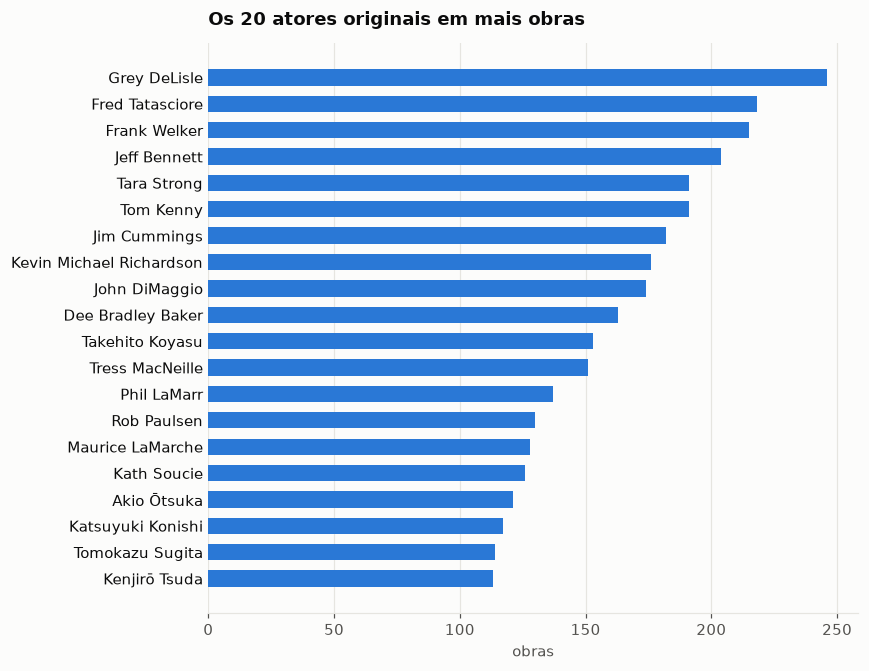

In [7]:
topa = ex.top_atores(rows, 20)
fig, ax = plt.subplots(figsize=(8, 6.2))
ex.barh(ax, [n for n, _, _ in topa], [o for _, o, _ in topa], "Os 20 atores originais em mais obras", "obras")
fig.tight_layout()
tabela([(n, f"{o} obras, {d} dubladores") for n, o, d in topa[:10]], ("ator original", "obras / dubladores distintos"))

## 6. A cauda longa: papéis por dublador

Poucos dubladores fazem a maior parte dos papéis. O gráfico ordena os dubladores do mais ao menos ativo, em escala log-log: a curva cai devagar nas primeiras centenas de posições (um núcleo profissional com centenas de papéis cada) e despenca depois, numa cauda de milhares de nomes com poucos papéis.

| dubladores | fazem |
|---|---:|
| 1% mais ativos | 24% dos papéis |
| 10% mais ativos | 84% dos papéis |
| 50% mais ativos | 99% dos papéis |

|  |  |
|---|---:|
| dubladores com 1 papel só | 2.593 |
| mediana de papéis | 2 |

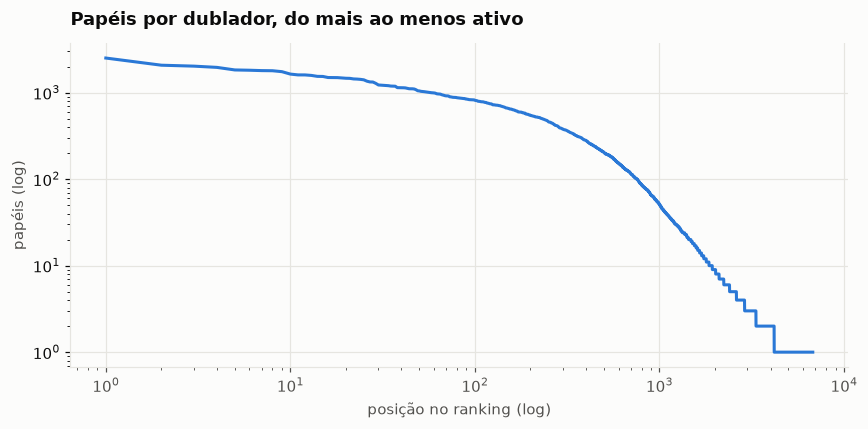

In [8]:
cont = ex.papeis_por_dublador(rows)
fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(range(1, len(cont) + 1), cont, color=ex.BLUE, linewidth=2)
ax.set_title("Papéis por dublador, do mais ao menos ativo")
ax.set_xlabel("posição no ranking (log)"); ax.set_ylabel("papéis (log)")
fig.tight_layout()
conc = ex.concentracao(cont)
tabela([(f"{int(f * 100)}% mais ativos", f"{v:.0f}% dos papéis") for f, v in conc.items()], ("dubladores", "fazem"))
tabela([("dubladores com 1 papel só", f"{sum(c == 1 for c in cont):,}".replace(",", ".")),
        ("mediana de papéis", sorted(cont)[len(cont) // 2])], ("", ""))

## 7. Estúdios e diretores de dublagem

Só entram as linhas em que o estúdio está ligado à versão certa (`unico` ou `casado`). Nas obras com várias dublagens sem indicação da versão (`ambiguo`), o estúdio fica de fora desta contagem.

| estudio_status | % das linhas |
|---|---:|
| unico | 73.3% |
| casado | 10.4% |
| ambiguo | 12.0% |
| vazio | 4.2% |

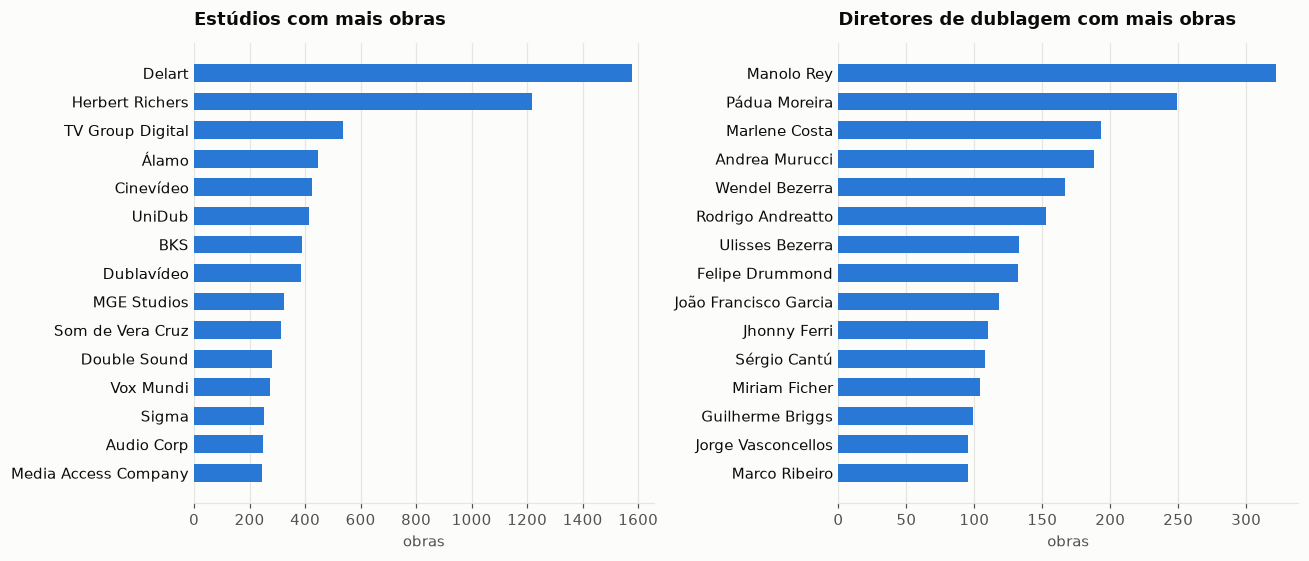

In [9]:
st, di = ex.top_estudios(rows, 15), ex.top_diretores(rows, 15)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
ex.barh(axes[0], [n for n, _ in st], [o for _, o in st], "Estúdios com mais obras", "obras")
ex.barh(axes[1], [n for n, _ in di], [o for _, o in di], "Diretores de dublagem com mais obras", "obras")
fig.tight_layout()
tabela([(k, f"{v:.1f}%") for k, v in ex.status_estudio(rows).items()], ("estudio_status", "% das linhas"))

## 8. Gênero

O gênero do ator original vem das categorias Atores/Atrizes da Dublapédia, então só existe para quem tem ficha. O do dublador quase não existe: as fichas de dublador não têm categoria por gênero e quase nunca preenchem o campo `sexo`. Por isso a parte "sem dado" domina; é uma lacuna da fonte, não da limpeza.

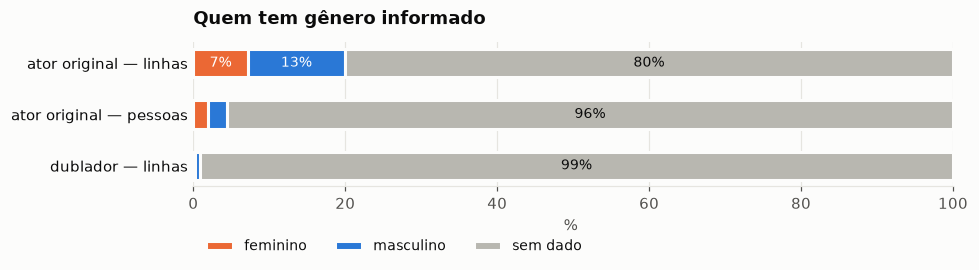

In [10]:
g = ex.genero(rows)
cats = [("F", "feminino", ex.ORANGE), ("M", "masculino", ex.BLUE), ("sem", "sem dado", ex.GRAY)]
fig, ax = plt.subplots(figsize=(9, 2.8))
labels = list(g)[::-1]
for i, k in enumerate(labels):
    left = 0
    for code, nome, cor in cats:
        v = g[k][code]
        ax.barh(i, v, left=left, height=0.55, color=cor, edgecolor=ex.SURFACE, linewidth=2,
                label=nome if i == 0 else None)
        if v >= 6: ax.text(left + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white" if code != "sem" else ex.INK, fontsize=9)
        left += v
ax.set_yticks(range(len(labels)), labels); ax.set_xlim(0, 100); ax.set_xlabel("% ")
ax.set_title("Quem tem gênero informado"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.28), fontsize=9)
fig.tight_layout()

## 9. Lacunas conhecidas

Percentual das linhas afetado por cada problema que ainda resta. As três maiores (gênero do dublador, gênero e ficha do ator original) dependem de fontes externas ou de inferência; as de estúdio dependem de cruzar com as fichas de dublador, que trazem o ano de cada trabalho.

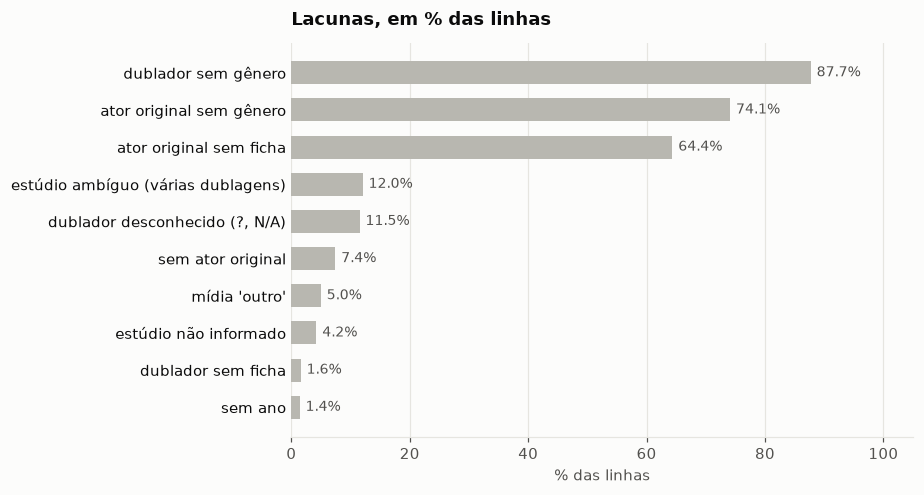

In [11]:
lac = sorted(ex.lacunas(rows).items(), key=lambda x: -x[1])
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ex.barh(ax, [k for k, _ in lac], [v for _, v in lac], "Lacunas, em % das linhas", "% das linhas", color=ex.GRAY)
for i, (_, v) in enumerate(lac[::-1]): ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=9, color=ex.INK2)
ax.set_xlim(0, 105)
fig.tight_layout()

## O que fica para a próxima etapa

- **Grafo**: dublador ↔ ator original com peso pelo número de obras; comunidades por estúdio e cidade.
- **Modelo**: prever o dublador de um personagem a partir do ator original, estúdio, década e mídia. O baseline é "o dublador mais frequente desse ator". Validar separando por franquia (`franquia`) para não vazar continuações entre treino e teste.
- **Lacunas a fechar antes**: gênero do dublador (primeiro nome) e do ator original (Wikidata), e variações de grafia dos atores sem ficha.